In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from aquarelab.baseline import extract_palette_kmeans
from aquarelab.recolor import assign_by_luminance, hex_to_lab, lab_to_rgb, recolor

In [12]:
img = Image.open("data/florest.jpg").convert("RGB")
img.thumbnail((512, 512))
image = np.asarray(img) / 255.0

In [13]:
palette, weights = extract_palette_kmeans(image, k=5)
new_palette = hex_to_lab(["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
matched = assign_by_luminance(palette, new_palette)
result = recolor(image, weights, palette, matched)

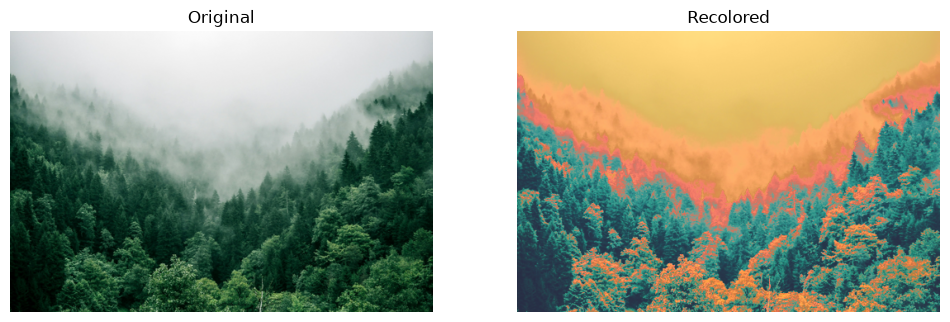

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image); axes[0].set_title("Original")
axes[1].imshow(result); axes[1].set_title("Recolored")
for ax in axes: ax.axis("off")
plt.savefig("figures/01_recolor.png", dpi=120, bbox_inches="tight")
plt.show()

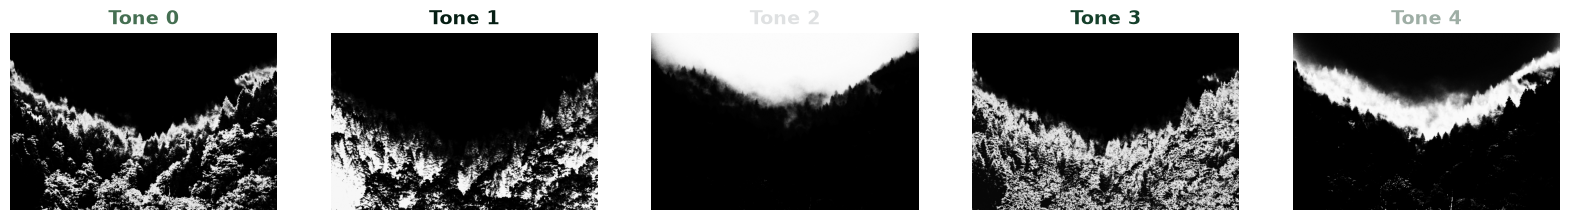

In [15]:
k = weights.shape[-1]
fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
for i in range(k):
    axes[i].imshow(weights[..., i], cmap="gray", vmin=0, vmax=1)
    swatch = lab_to_rgb(palette[i][None, None, :])[0, 0]
    axes[i].set_title(f"Tone {i}", color=swatch, fontsize=14, fontweight="bold")
    axes[i].axis("off")
plt.savefig("figures/01_tone_maps.png", dpi=120, bbox_inches="tight")
plt.show()